Projet Machine Learning — Estimation de la capacité d'investissement

1. Business Understanding

1.1 Contexte du projet

Dans le secteur bancaire, il est important de connaître la capacité financière des clients afin de leur proposer des produits et services adaptés à leur profil.

1.2 Business Objective

L'objectif métier est d'aider la banque à estimer combien un client peut investir, afin de lui proposer les produits financiers les plus adaptés à sa situation.

1.3 Data Science Objective

L'objectif de ce projet est de prédire la valeur des actifs bancaires d'un client à partir de son profil financier.

1.4 Type de problème

Il s'agit d'un problème de régression supervisée, car la variable cible bank_asset_value est une variable numérique.

1.5 Méthodes utilisées

Deux modèles de régression seront étudiés :

Ridge Regression

Lasso Regression

Ces modèles permettront de comparer les performances obtenues pour la prédiction de la valeur des actifs bancaires.

# Méthodologie CRISP-DM

Ce projet suit la méthodologie **CRISP-DM (Cross-Industry Standard Process for Data Mining)**.

Les différentes étapes suivies sont :

1. **Business Understanding** — compréhension du problème métier
2. **Data Understanding** — compréhension et exploration des données
3. **Data Preparation** — préparation et nettoyage des données
4. **Modeling** — construction des modèles de régression
5. **Evaluation** — évaluation et comparaison des modèles
6. **Conclusion** — interprétation des résultats et bilan du projet

In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:

import os
import zipfile

# Chemin de l'archive conservée dans Google Drive
zip_path = "/content/drive/MyDrive/ML-project/archive.zip"

# Dossier temporaire pour les données extraites
extract_path = "/content/dataset"

# Vérifier que l'archive existe
if not os.path.exists(zip_path):
    raise FileNotFoundError(
        f"Archive introuvable : {zip_path}. Vérifie son emplacement dans Google Drive."
    )

# Extraire les fichiers
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Archive extraite avec succès !")
print("Fichiers disponibles :", os.listdir(extract_path)[:10])


Archive extraite avec succès !
Fichiers disponibles : ['loan_approval_dataset.csv']


In [37]:
df = pd.read_csv("/content/dataset/loan_approval_dataset.csv")

df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [38]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 4269
Nombre de colonnes : 13


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [40]:
print(df.columns.tolist())

['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']


In [41]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [42]:
df.isnull().sum()

,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


In [43]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


### 2.1 Identification des types de variables

L'analyse des types de données permet de distinguer les variables numériques des variables catégorielles. Cette distinction est importante afin de déterminer les traitements nécessaires lors de la phase de préparation des données.

In [44]:
# Variables numériques
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Variables catégorielles
categorical_columns = df.select_dtypes(include=['object']).columns

print("Variables numériques :")
print(list(numeric_columns))

print("\nVariables catégorielles :")
print(list(categorical_columns))

Variables numériques :
['loan_id', ' no_of_dependents', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value']

Variables catégorielles :
[' education', ' self_employed', ' loan_status']


### 2.2 Analyse de la variable cible

La variable cible du projet est `bank_asset_value`. Il s'agit d'une variable quantitative représentant la valeur des actifs bancaires du client.

Une analyse de sa distribution permet de mieux comprendre les valeurs à prédire et d'identifier d'éventuelles valeurs atypiques.

In [45]:
target = ' bank_asset_value'

print("Statistiques de bank_asset_value :")
print(df[target].describe())

Statistiques de bank_asset_value :
count    4.269000e+03
mean     4.976692e+06
std      3.250185e+06
min      0.000000e+00
25%      2.300000e+06
50%      4.600000e+06
75%      7.100000e+06
max      1.470000e+07
Name:  bank_asset_value, dtype: float64


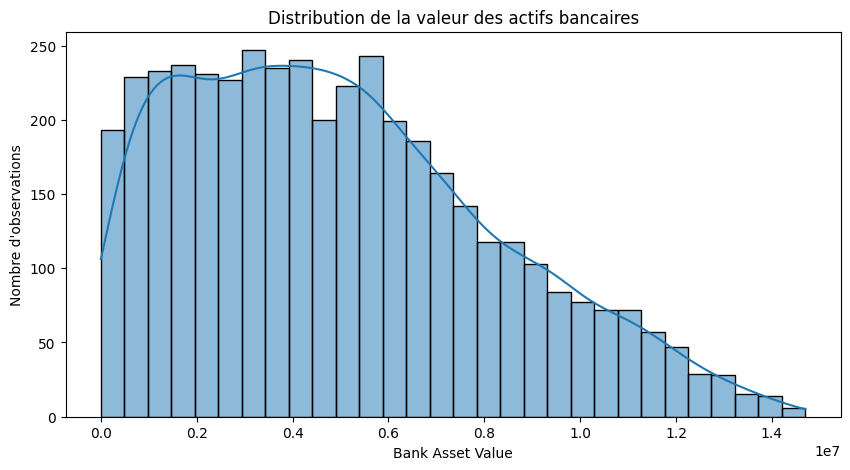

In [46]:
plt.figure(figsize=(10, 5))

sns.histplot(df[target], bins=30, kde=True)

plt.title("Distribution de la valeur des actifs bancaires")
plt.xlabel("Bank Asset Value")
plt.ylabel("Nombre d'observations")

plt.show()

In [47]:
for col in categorical_columns:
    print("\n---", col, "---")
    print(df[col].value_counts())


---  education ---
 education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

---  self_employed ---
 self_employed
Yes    2150
No     2119
Name: count, dtype: int64

---  loan_status ---
 loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


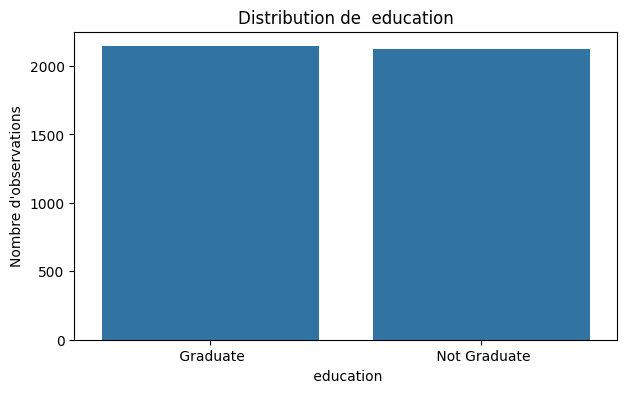

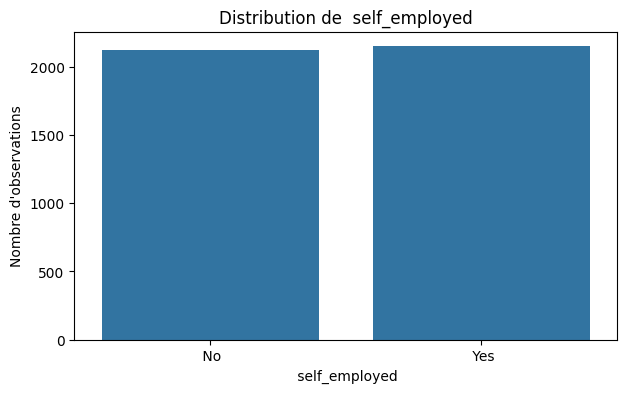

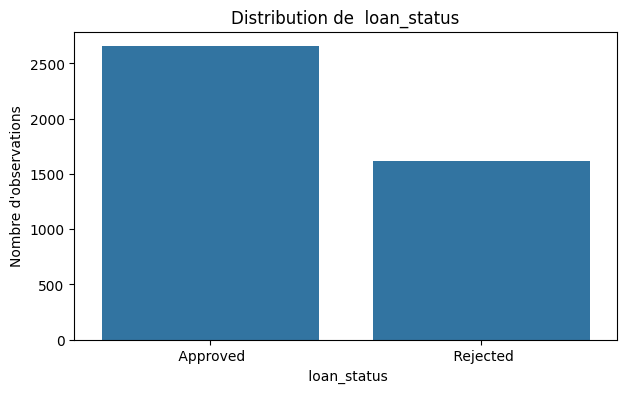

In [48]:
for col in categorical_columns:
    plt.figure(figsize=(7, 4))

    sns.countplot(data=df, x=col)

    plt.title(f"Distribution de {col}")
    plt.xlabel(col)
    plt.ylabel("Nombre d'observations")
    plt.xticks(rotation=0)

    plt.show()

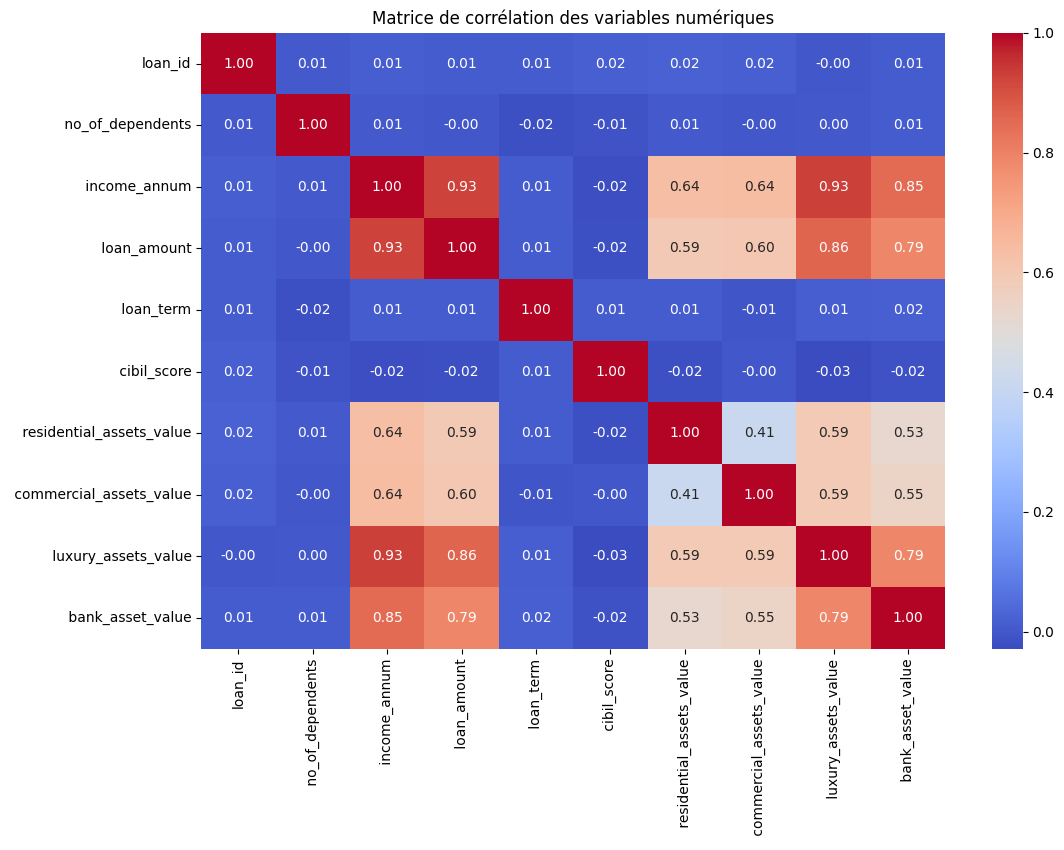

In [49]:
# Sélection des variables numériques
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calcul de la matrice de corrélation
correlation_matrix = numeric_df.corr()

# Affichage de la matrice
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Matrice de corrélation des variables numériques")
plt.show()

In [50]:
# Corrélation de chaque variable numérique avec bank_asset_value
target_correlation = correlation_matrix[' bank_asset_value'].sort_values(ascending=False)

print("Corrélation avec bank_asset_value :")
print(target_correlation)

Corrélation avec bank_asset_value :
 bank_asset_value            1.000000
 income_annum                0.851093
 luxury_assets_value         0.788517
 loan_amount                 0.788122
 commercial_assets_value     0.548576
 residential_assets_value    0.527418
 loan_term                   0.017177
 no_of_dependents            0.011163
loan_id                      0.010765
 cibil_score                -0.015478
Name:  bank_asset_value, dtype: float64


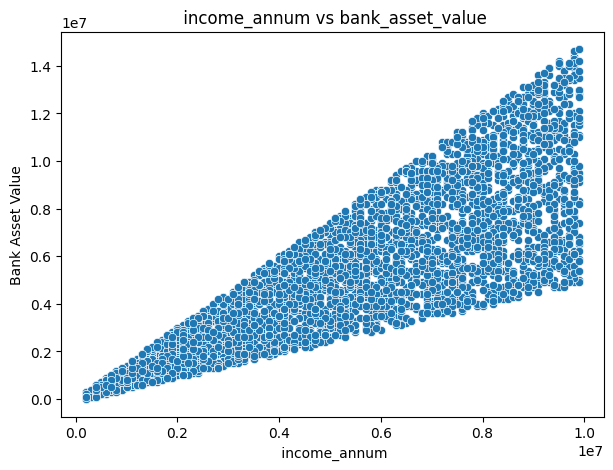

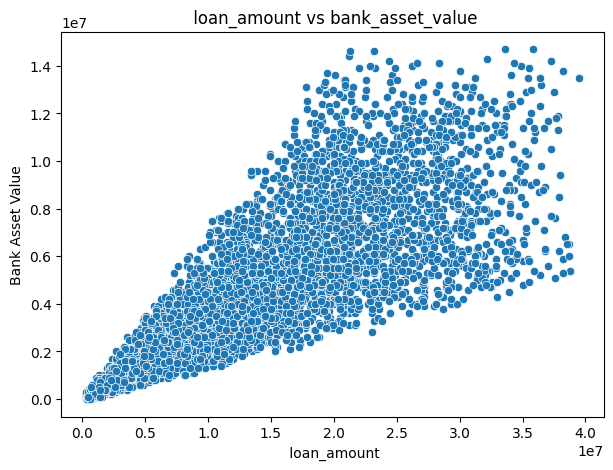

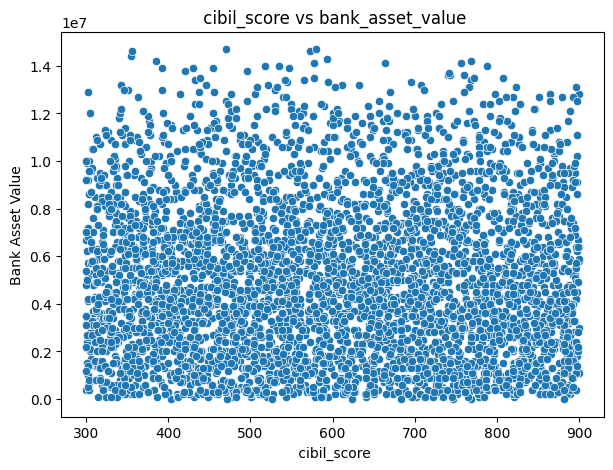

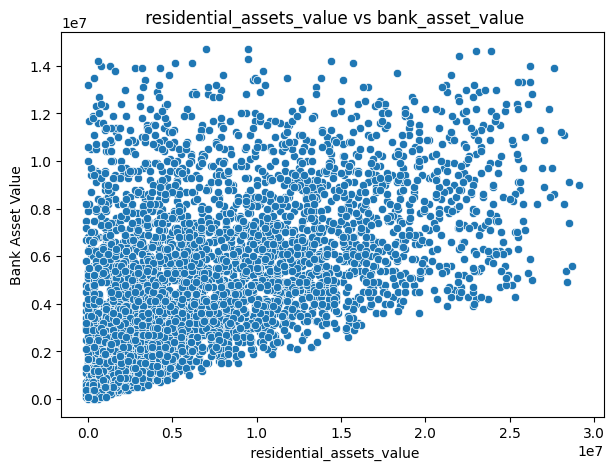

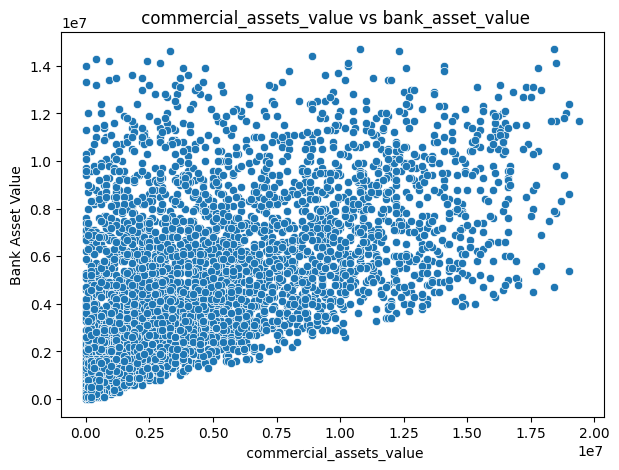

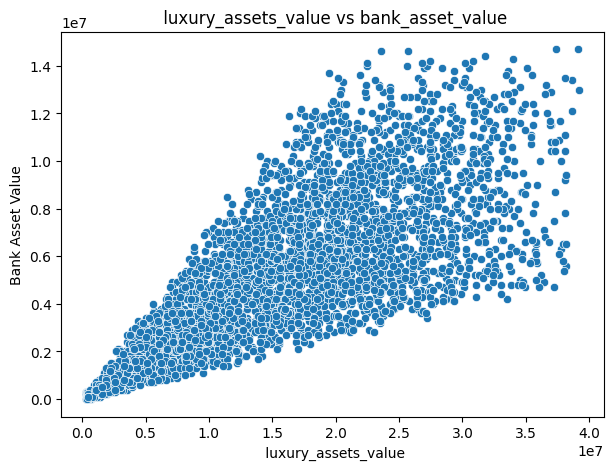

In [51]:
features_to_plot = [
    ' income_annum',
    ' loan_amount',
    ' cibil_score',
    ' residential_assets_value',
    ' commercial_assets_value',
    ' luxury_assets_value'
]

for col in features_to_plot:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=col, y=' bank_asset_value')
    plt.title(f"{col} vs bank_asset_value")
    plt.xlabel(col)
    plt.ylabel("Bank Asset Value")
    plt.show()

### Analyse des corrélations

L'analyse de la matrice de corrélation permet d'étudier les relations linéaires entre les variables numériques et la variable cible `bank_asset_value`.

Les résultats montrent que `income_annum` présente la corrélation la plus forte avec `bank_asset_value`, avec un coefficient de **0,851**. Cela indique une relation positive forte entre le revenu annuel du client et la valeur de ses actifs bancaires.

Les variables `luxury_assets_value` (**0,789**) et `loan_amount` (**0,788**) présentent également de fortes corrélations positives avec la variable cible. Les variables `commercial_assets_value` (**0,549**) et `residential_assets_value` (**0,527**) présentent quant à elles des corrélations positives modérées.

En revanche, `loan_term` (**0,017**), `no_of_dependents` (**0,011**) et `cibil_score` (**-0,015**) présentent une très faible corrélation linéaire avec `bank_asset_value`. La variable `loan_id` est également une variable d'identification et ne présente pas de relation pertinente avec la variable cible.

Ces résultats permettent d'identifier les variables potentiellement les plus importantes pour la modélisation. Cependant, aucune variable ne sera supprimée uniquement sur la base de sa corrélation. Une analyse complémentaire sera réalisée lors de la préparation des données et de la modélisation avec les méthodes Ridge et Lasso.

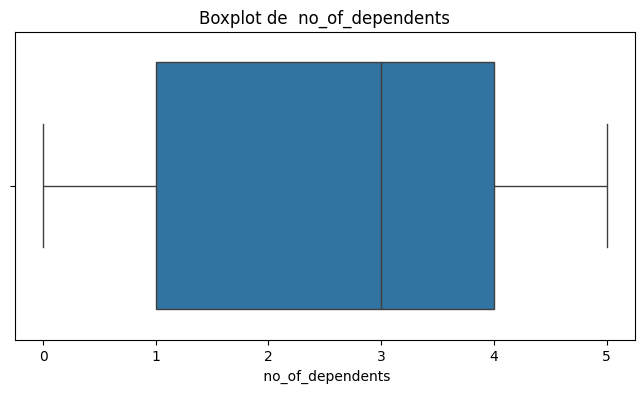

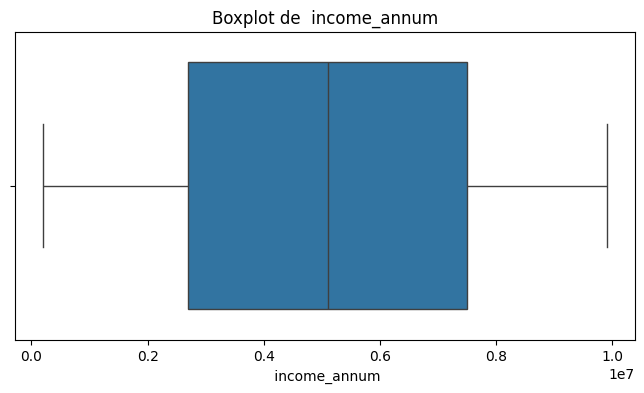

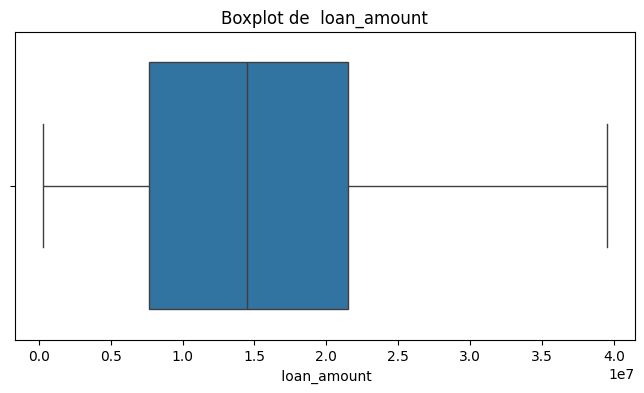

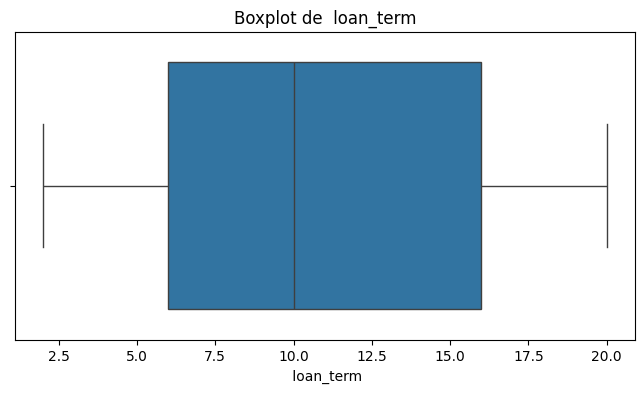

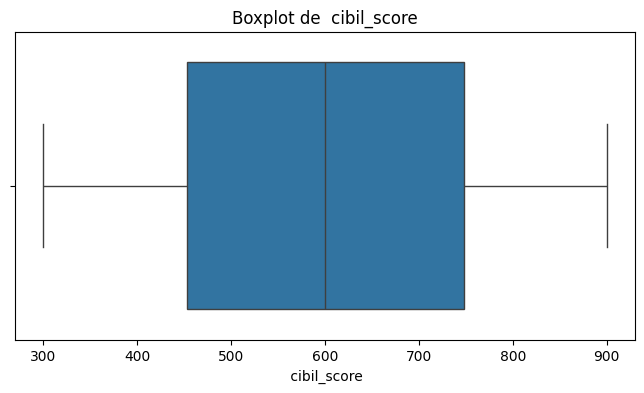

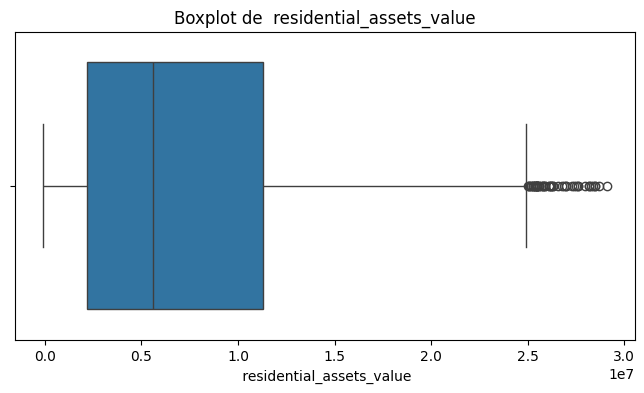

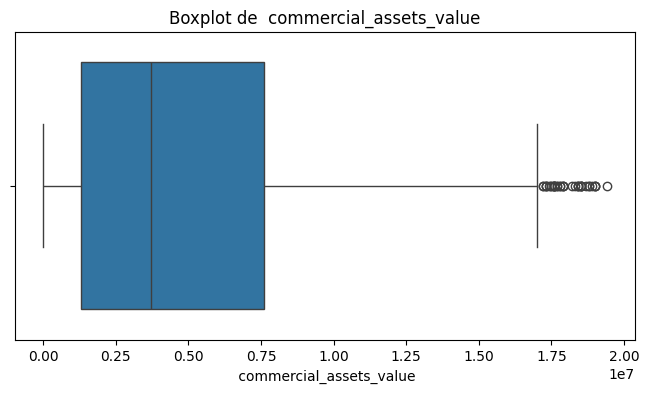

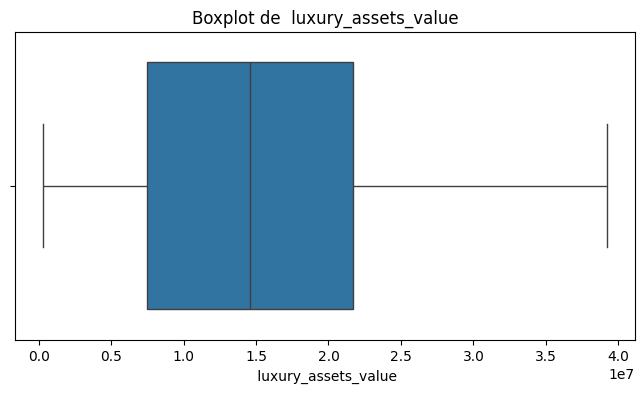

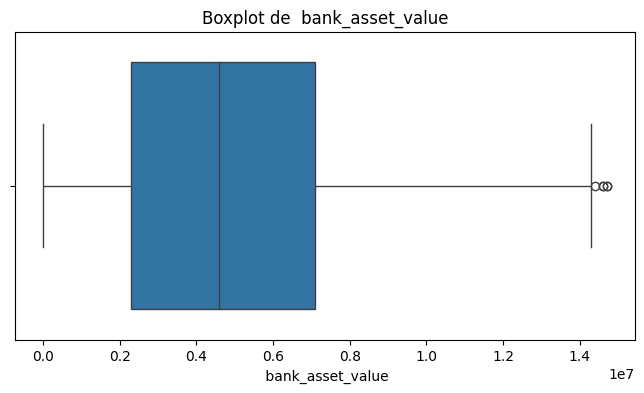

In [52]:
# Détection visuelle des valeurs aberrantes
numeric_features = [
    ' no_of_dependents',
    ' income_annum',
    ' loan_amount',
    ' loan_term',
    ' cibil_score',
    ' residential_assets_value',
    ' commercial_assets_value',
    ' luxury_assets_value',
    ' bank_asset_value'
]

for col in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

In [53]:
# Recherche des valeurs minimales et maximales
for col in numeric_features:
    print(f"{col} :")
    print("  Minimum :", df[col].min())
    print("  Maximum :", df[col].max())
    print()

 no_of_dependents :
  Minimum : 0
  Maximum : 5

 income_annum :
  Minimum : 200000
  Maximum : 9900000

 loan_amount :
  Minimum : 300000
  Maximum : 39500000

 loan_term :
  Minimum : 2
  Maximum : 20

 cibil_score :
  Minimum : 300
  Maximum : 900

 residential_assets_value :
  Minimum : -100000
  Maximum : 29100000

 commercial_assets_value :
  Minimum : 0
  Maximum : 19400000

 luxury_assets_value :
  Minimum : 300000
  Maximum : 39200000

 bank_asset_value :
  Minimum : 0
  Maximum : 14700000



### Analyse des valeurs extrêmes

L'analyse des valeurs minimales et maximales montre que la majorité des variables présentent des intervalles de valeurs cohérents. Cependant, une valeur négative a été détectée pour la variable `residential_assets_value`, dont le minimum est de **-100 000**.

Cette valeur étant inhabituelle pour une variable représentant la valeur des actifs résidentiels, elle sera vérifiée avant toute décision de traitement. Aucune valeur n'est supprimée à ce stade.

In [54]:
# Recherche des valeurs négatives pour les actifs résidentiels
negative_residential = df[df[' residential_assets_value'] < 0]

print("Nombre de valeurs négatives :", len(negative_residential))
negative_residential

Nombre de valeurs négatives : 28


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,4,Not Graduate,Yes,5500000,18200000,16,797,-100000,4900000,18600000,4800000,Approved
196,197,4,Not Graduate,Yes,400000,1500000,2,669,-100000,600000,900000,500000,Approved
559,560,2,Graduate,Yes,200000,500000,6,885,-100000,0,300000,200000,Rejected
702,703,4,Graduate,Yes,6300000,23900000,6,899,-100000,11400000,20600000,6700000,Approved
737,738,2,Graduate,Yes,900000,2500000,16,458,-100000,100000,3200000,1100000,Rejected
784,785,0,Graduate,No,5000000,14400000,2,761,-100000,7300000,12600000,4500000,Approved
904,905,2,Graduate,No,4100000,14900000,12,571,-100000,5200000,13000000,3400000,Approved
1089,1090,3,Graduate,No,5100000,11000000,6,336,-100000,5800000,11600000,7500000,Rejected
1163,1164,2,Graduate,No,4500000,9100000,18,593,-100000,600000,12400000,2500000,Approved
1350,1351,5,Graduate,No,4000000,13700000,6,496,-100000,1400000,15800000,3700000,Rejected


In [55]:
# Statistiques de residential_assets_value sans les valeurs négatives

valid_residential = df[df[' residential_assets_value'] >= 0][' residential_assets_value']

print("Nombre de valeurs valides :", len(valid_residential))
print("Moyenne :", valid_residential.mean())
print("Médiane :", valid_residential.median())
print("Minimum :", valid_residential.min())
print("Maximum :", valid_residential.max())

Nombre de valeurs valides : 4241
Moyenne : 7522612.5913699595
Médiane : 5700000.0
Minimum : 0
Maximum : 29100000


In [56]:
# Statistiques de residential_assets_value sans les valeurs négatives

valid_residential = df[df[' residential_assets_value'] >= 0][' residential_assets_value']

print("Nombre de valeurs valides :", len(valid_residential))
print("Moyenne :", valid_residential.mean())
print("Médiane :", valid_residential.median())
print("Minimum :", valid_residential.min())
print("Maximum :", valid_residential.max())

Nombre de valeurs valides : 4241
Moyenne : 7522612.5913699595
Médiane : 5700000.0
Minimum : 0
Maximum : 29100000


### Traitement des valeurs aberrantes

L’analyse de la variable `residential_assets_value` a permis d’identifier **28 valeurs négatives**, toutes égales à **-100 000**. Ces valeurs sont considérées comme anormales pour une variable représentant la valeur des actifs résidentiels.

Afin de conserver les observations concernées sans introduire de valeurs négatives invalides dans le modèle, ces valeurs ont été remplacées par des valeurs manquantes (`NaN`).

L’imputation par la médiane sera réalisée après la séparation des données en ensembles d’entraînement et de test. La médiane sera calculée uniquement à partir des données d’entraînement, puis appliquée aux deux ensembles. Cette méthode permet de conserver les observations tout en évitant les fuites de données.

La médiane est privilégiée à la moyenne, car elle est moins sensible aux valeurs extrêmes présentes dans la variable.

**À ce stade, les valeurs négatives ont été identifiées et remplacées par `NaN` ; l’imputation n’a pas encore été effectuée.**

In [57]:

# Remplacer les valeurs négatives invalides par NaN
# L'imputation par la médiane sera réalisée après la séparation
# en utilisant uniquement les données d'entraînement.

df.loc[
    df[' residential_assets_value'] < 0,
    ' residential_assets_value'
] = np.nan

print(
    "Valeurs invalides remplacées par NaN :",
    df[' residential_assets_value'].isna().sum()
)


Valeurs invalides remplacées par NaN : 28


In [58]:

print("Statistiques de residential_assets_value :")
print(df[' residential_assets_value'].describe())

print(
    "Valeurs manquantes :",
    df[' residential_assets_value'].isna().sum()
)


Statistiques de residential_assets_value :
count    4.241000e+03
mean     7.522613e+06
std      6.495800e+06
min      0.000000e+00
25%      2.200000e+06
50%      5.700000e+06
75%      1.140000e+07
max      2.910000e+07
Name:  residential_assets_value, dtype: float64
Valeurs manquantes : 28



## 3. Data Preparation

Cette phase consiste à nettoyer, transformer et organiser les données afin de les rendre exploitables par les modèles de régression Ridge et Lasso.

Les opérations réalisées sont :

- Nettoyage des noms de colonnes.
- Traitement des valeurs invalides détectées lors de l'analyse exploratoire.
- Vérification des valeurs manquantes et des doublons.
- Sélection des variables explicatives et de la variable cible.
- Séparation des données en ensembles d'entraînement et de test.
- Imputation des valeurs manquantes à partir des données d'entraînement.
- Encodage des variables catégorielles.
- Standardisation des variables pour préparer les modèles.


In [59]:
# Nettoyage des noms de colonnes
df.columns = df.columns.str.strip()

# Vérification
print(df.columns.tolist())

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [60]:

print("Valeurs négatives dans residential_assets_value :",
      (df['residential_assets_value'] < 0).sum())

print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())

print("\nNombre de doublons :", df.duplicated().sum())


Valeurs négatives dans residential_assets_value : 0

Valeurs manquantes par colonne :
loan_id                      0
no_of_dependents             0
education                    0
self_employed                0
income_annum                 0
loan_amount                  0
loan_term                    0
cibil_score                  0
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
loan_status                  0
dtype: int64

Nombre de doublons : 0


In [61]:

# Suppression des identifiants et des variables non retenues
# loan_id est un identifiant.
# loan_status est exclue car elle peut apporter une information
# liée à la décision d'octroi du prêt.

df_model = df.drop(
    columns=['loan_id', 'loan_status'],
    errors='ignore'
)

# Séparation de la cible et des variables explicatives
y = df_model['bank_asset_value']

# Sélection des 5 variables explicatives retenues
features = [
    'income_annum',
    'luxury_assets_value',
    'loan_amount',
    'commercial_assets_value',
    'residential_assets_value'
]

X = df_model[features].copy()

# Vérification du résultat
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

print("\nVariables explicatives retenues :")
print(X.columns.tolist())

print("\nVariable cible :", y.name)


Dimensions de X : (4269, 5)
Dimensions de y : (4269,)

Variables explicatives retenues :
['income_annum', 'luxury_assets_value', 'loan_amount', 'commercial_assets_value', 'residential_assets_value']

Variable cible : bank_asset_value


In [62]:
print(X.dtypes)

income_annum                  int64
luxury_assets_value           int64
loan_amount                   int64
commercial_assets_value       int64
residential_assets_value    float64
dtype: object



### Séparation des données

Après l'analyse et le nettoyage initial des données, le dataset est séparé en deux ensembles :

- **Ensemble d'entraînement (80 %)** : utilisé pour préparer les variables et entraîner les modèles.
- **Ensemble de test (20 %)** : conservé pour évaluer les modèles sur des observations non utilisées pendant l'entraînement.

La séparation est effectuée avant l'imputation par la médiane, l'encodage et la standardisation afin d'éviter les fuites de données.


In [63]:

from sklearn.model_selection import train_test_split

# Séparation des données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)
print("Taille de y_train :", y_train.shape)
print("Taille de y_test  :", y_test.shape)


Taille de X_train : (3415, 5)
Taille de X_test  : (854, 5)
Taille de y_train : (3415,)
Taille de y_test  : (854,)


In [64]:

# 1. Imputation des valeurs manquantes
# La médiane est calculée uniquement sur l'ensemble d'entraînement.

median_residential = X_train['residential_assets_value'].median()

X_train = X_train.copy()
X_test = X_test.copy()

X_train['residential_assets_value'] = (
    X_train['residential_assets_value'].fillna(median_residential)
)

X_test['residential_assets_value'] = (
    X_test['residential_assets_value'].fillna(median_residential)
)

print("Valeurs manquantes après imputation :")
print("Train :", X_train.isnull().sum().sum())
print("Test  :", X_test.isnull().sum().sum())



# 2. Encodage des variables catégorielles
# Aucune variable catégorielle n'est conservée dans X.
# Les 5 variables retenues sont toutes numériques.

print("Aucun encodage catégoriel nécessaire.")

# Vérifier les colonnes conservées
print("\nVariables explicatives :")
print(X_train.columns.tolist())





print("\nDimensions après encodage :")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

print("\nColonnes utilisées :")
print(X_train.columns.tolist())

print("\nTypes des variables après encodage :")
print(X_train.dtypes)


Valeurs manquantes après imputation :
Train : 0
Test  : 0
Aucun encodage catégoriel nécessaire.

Variables explicatives :
['income_annum', 'luxury_assets_value', 'loan_amount', 'commercial_assets_value', 'residential_assets_value']

Dimensions après encodage :
X_train : (3415, 5)
X_test  : (854, 5)

Colonnes utilisées :
['income_annum', 'luxury_assets_value', 'loan_amount', 'commercial_assets_value', 'residential_assets_value']

Types des variables après encodage :
income_annum                  int64
luxury_assets_value           int64
loan_amount                   int64
commercial_assets_value       int64
residential_assets_value    float64
dtype: object


In [65]:

from sklearn.preprocessing import StandardScaler

# Initialisation du standardiseur
scaler = StandardScaler()

# Apprentissage du standardiseur uniquement sur les données d'entraînement
X_train_scaled = scaler.fit_transform(X_train)

# Application des mêmes paramètres aux données de test
X_test_scaled = scaler.transform(X_test)

print("Dimensions de X_train_scaled :", X_train_scaled.shape)
print("Dimensions de X_test_scaled  :", X_test_scaled.shape)

print("\nVérification des valeurs manquantes :")
print("Train :", np.isnan(X_train_scaled).sum())
print("Test  :", np.isnan(X_test_scaled).sum())


Dimensions de X_train_scaled : (3415, 5)
Dimensions de X_test_scaled  : (854, 5)

Vérification des valeurs manquantes :
Train : 0
Test  : 0


# 4. Modeling (Modélisation)

Cette étape consiste à entraîner des modèles de régression capables de prédire la valeur des actifs bancaires (`bank_asset_value`) à partir des cinq variables explicatives sélectionnées.

Deux algorithmes sont retenus : **Ridge Regression** et **Lasso Regression**. Ces deux modèles sont basés sur la régression linéaire et intègrent une régularisation permettant de limiter la complexité du modèle et de réduire le risque de surapprentissage.

- **Ridge Regression** utilise une régularisation L2, qui réduit l'amplitude des coefficients sans les annuler directement.
- **Lasso Regression** utilise une régularisation L1, qui peut réduire certains coefficients jusqu'à zéro et ainsi contribuer à la sélection des variables.

Les deux modèles seront entraînés sur les mêmes données afin de pouvoir comparer leurs performances lors de la phase d'évaluation.

In [66]:

# Importation des modèles
from sklearn.linear_model import Ridge, Lasso
from sklearn.svm import SVR

# 1. Création des modèles
ridge_model = Ridge(alpha=1.0)

lasso_model = Lasso(
    alpha=1.0,
    max_iter=10000
)

svr_model = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1
)

# 2. Entraînement sur les données standardisées
ridge_model.fit(X_train_scaled, y_train)
lasso_model.fit(X_train_scaled, y_train)
svr_model.fit(X_train_scaled, y_train)

print("Les trois modèles ont été entraînés avec succès.")

# 3. Vérification des dimensions
print("\nDimensions des données d'entraînement :",
      X_train_scaled.shape)

print("Nombre de valeurs cibles d'entraînement :",
      y_train.shape[0])


Les trois modèles ont été entraînés avec succès.

Dimensions des données d'entraînement : (3415, 5)
Nombre de valeurs cibles d'entraînement : 3415


# 5. Evaluation (Évaluation)

Cette étape consiste à évaluer les performances des trois modèles entraînés : Ridge Regression, Lasso Regression et Support Vector Regression (SVR).

Les modèles seront évalués sur les données de test, qui n'ont pas été utilisées pendant leur entraînement. Trois métriques seront utilisées pour comparer leurs performances : la MAE, la RMSE et le coefficient de détermination R².

L'objectif est d'identifier le modèle qui prédit le plus précisément la variable cible `bank_asset_value` et qui généralise le mieux sur de nouvelles données.

In [67]:

# Importation des métriques
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Prédictions sur les données de test
y_pred_ridge = ridge_model.predict(X_test_scaled)
y_pred_lasso = lasso_model.predict(X_test_scaled)
y_pred_svr = svr_model.predict(X_test_scaled)

# 2. Fonction d'évaluation
def evaluer_modele(nom, y_reel, y_pred):
    mae = mean_absolute_error(y_reel, y_pred)
    rmse = np.sqrt(mean_squared_error(y_reel, y_pred))
    r2 = r2_score(y_reel, y_pred)

    return {
        'Modèle': nom,
        'MAE': mae,
        'RMSE': rmse,
        'R²': r2
    }

# 3. Comparaison des trois modèles
resultats = pd.DataFrame([
    evaluer_modele('Ridge Regression', y_test, y_pred_ridge),
    evaluer_modele('Lasso Regression', y_test, y_pred_lasso),
    evaluer_modele('SVR', y_test, y_pred_svr)
])

# 4. Affichage des résultats
print("Comparaison des performances :")
display(resultats.round(3))


Comparaison des performances :


,Modèle,MAE,RMSE,R²
0,Ridge Regression,1301129.749,1710791.608,0.734
1,Lasso Regression,1301075.566,1710698.928,0.734
2,SVR,2713042.863,3365880.133,-0.031


In [68]:
import pandas as pd

coefficients = pd.DataFrame({
    'Variable': X.columns,
    'Ridge': ridge_model.coef_,
    'Lasso': lasso_model.coef_
})

display(coefficients.round(3))

,Variable,Ridge,Lasso
0,income_annum,2835513.552,2848343.463
1,luxury_assets_value,-6867.473,-12719.053
2,loan_amount,-86099.085,-91933.387
3,commercial_assets_value,67649.058,66796.758
4,residential_assets_value,-75171.777,-76123.526


### Conclusion de l'évaluation

L'évaluation des trois modèles montre que Ridge Regression et Lasso Regression obtiennent des performances très proches, avec un coefficient de détermination R² de 0,734. Lasso présente des erreurs légèrement plus faibles, avec une MAE de 1 301 075,566 et une RMSE de 1 710 698,928.

En revanche, le modèle SVR obtient un R² négatif de -0,031, ce qui indique qu'il est moins performant qu'une prédiction de référence basée sur la moyenne des valeurs cibles sur les données de test.

L'analyse des coefficients montre également que le revenu annuel (`income_annum`) est la variable associée au coefficient le plus élevé en valeur absolue dans les modèles linéaires. Le choix définitif du modèle devra toutefois tenir compte d'une validation complémentaire de ses performances.